# Nifty 50 Quantitative Backtesting
Feature engineering, rule-based signals and a walk-forward XGBoost model on Nifty 50 daily data, evaluated with risk-adjusted metrics.

**Design rules:** long/flat only, signal at close of day *t* traded at close of day *t+1* (no look-ahead), transaction cost charged on every position change, ML model retrained only on past data.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd
import matplotlib.pyplot as plt
from src.nifty_backtest import *

pd.set_option('display.float_format', '{:.3f}'.format)
# SYNTHETIC is only used to smoke-test the notebook offline. Leave it unset for real runs.
SYNTHETIC = os.environ.get('NIFTY_SYNTHETIC') == '1'

## 1. Data
Nifty 50 index (`^NSEI`) daily OHLCV from Yahoo Finance.

In [2]:
df = load_data(ticker='^NSEI', start='2010-01-01', synthetic=SYNTHETIC)
print(df.index[0].date(), 'to', df.index[-1].date(), len(df), 'trading days')
df.tail()

/Users/chinmayatejavasala/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


2010-01-04 to 2026-11-23 4148 trading days


Price,Open,High,Low,Close,Volume
Date,,,,,
2026-11-17,25277.301,25501.350,25267.301,25387.400,342500
2026-11-18,25323.150,25390.801,25141.801,25227.949,300000
2026-11-19,25186.801,25514.301,25104.801,25514.301,328800
2026-11-20,25368.000,25808.801,25345.199,25800.600,428300
2026-11-23,25929.150,25992.600,25343.850,25349.650,519100


## 2. Feature engineering
SMA(10/50) ratio, RSI(14), 20-day Z-score, 20-day volatility, 5/20-day momentum and the daily return. Every feature at day *t* uses data up to *t* only.

In [3]:
feat = add_features(df)
feat[['Close'] + FEATURES].dropna().tail()

Price,Close,sma_ratio,rsi_14,zscore_20,vol_20,mom_5,mom_20,ret
Date,,,,,,,,
2026-11-17,25387.400,0.064,78.105,1.357,0.009,0.014,0.097,0.004
2026-11-18,25227.949,0.069,73.336,1.096,0.009,-0.001,0.102,-0.006
2026-11-19,25514.301,0.074,76.152,1.215,0.009,0.008,0.118,0.011
2026-11-20,25800.600,0.077,78.587,1.321,0.008,0.026,0.137,0.011
2026-11-23,25349.650,0.077,66.986,0.846,0.010,0.002,0.122,-0.017


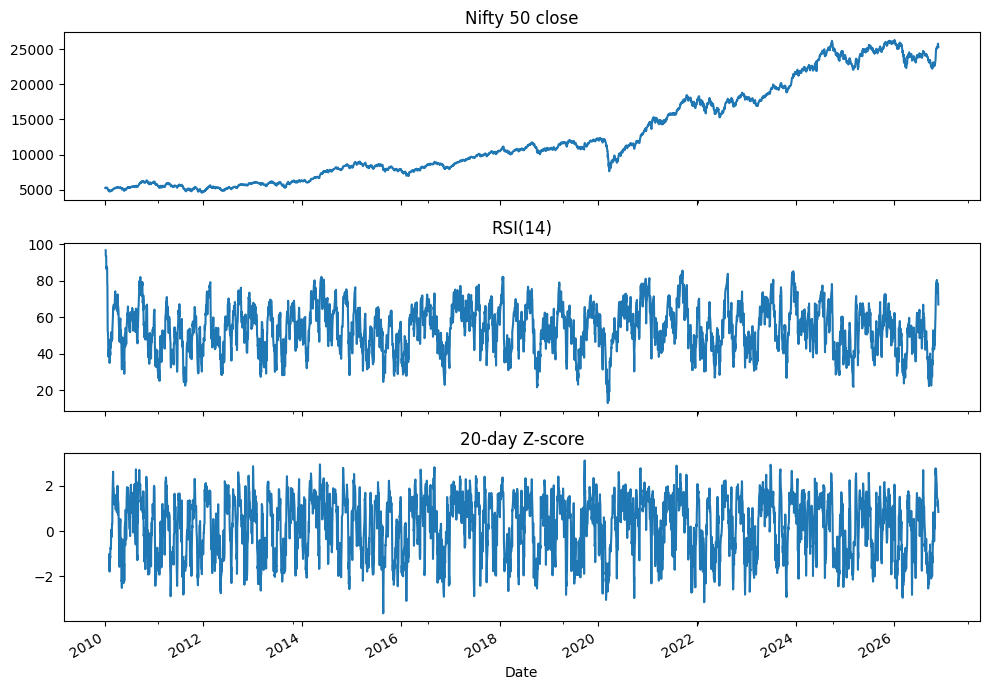

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
feat['Close'].plot(ax=ax[0], title='Nifty 50 close')
feat['rsi_14'].plot(ax=ax[1], title='RSI(14)')
feat['zscore_20'].plot(ax=ax[2], title='20-day Z-score')
plt.tight_layout(); plt.show()

## 3. Signals
- **MA crossover:** long when SMA10 > SMA50.
- **Mean reversion:** enter long at Z < -1, exit at Z >= 0.
- **XGBoost:** expanding-window walk-forward, retrained every 252 days (first model after 3 years of data), predicts next-day direction, long if P(up) > 0.5.

In [5]:
signals = {
    'MA Crossover': signal_ma_cross(feat),
    'Mean Reversion': signal_mean_reversion(feat),
    'XGBoost (walk-forward)': signal_xgboost_walk_forward(feat),
}
{k: v.dropna().mean().round(3) for k, v in signals.items()}  # fraction of time invested

{'MA Crossover': np.float64(0.639),
 'Mean Reversion': np.float64(0.321),
 'XGBoost (walk-forward)': np.float64(0.558)}

## 4. Backtest and evaluation
All strategies and buy-and-hold are compared over the **same out-of-sample window** (where the walk-forward model has predictions). Cost: 5 bps per position change. Risk-free rate set to 0 for the Sharpe ratio.

In [6]:
table, rets = evaluate_all(df, cost_bps=5.0)
print('Window:', rets.index[0].date(), 'to', rets.index[-1].date())
table

Window: 2013-04-15 to 2026-11-23


,Ann. Return,Ann. Vol,Sharpe,Max Drawdown,Win Rate (active days),Round Trips
Buy and Hold,0.121,0.162,0.788,-0.384,0.536,0.000
MA Crossover,0.087,0.106,0.838,-0.161,0.540,38.000
Mean Reversion,0.024,0.119,0.257,-0.357,0.511,100.000
XGBoost (walk-forward),0.028,0.128,0.280,-0.389,0.539,602.000


In [7]:
os.makedirs('../results', exist_ok=True)
table.to_csv('../results/metrics.csv')
plot_results(rets, '../results/equity_curves.png')
(1 + rets).cumprod().plot(figsize=(10, 4), title='Out-of-sample equity curves (growth of 1)'); plt.grid(alpha=0.3); plt.show()

/var/folders/f8/l8m6mkgx2dl9wcj07mhh1yj80000gn/T/ipykernel_34963/3701155788.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (1 + rets).cumprod().plot(figsize=(10, 4), title='Out-of-sample equity curves (growth of 1)'); plt.grid(alpha=0.3); plt.show()


## 5. Feature importance (final model)

In [8]:
from xgboost import XGBClassifier
d = feat.dropna(subset=FEATURES).copy()
d['target'] = (d['ret'].shift(-1) > 0).astype(int)
d = d.iloc[:-1]
m = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric='logloss').fit(d[FEATURES], d['target'])
imp = pd.Series(m.feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(7, 4)); plt.barh(imp.index, imp.values); plt.title('XGBoost feature importance')
plt.tight_layout(); plt.show()

/var/folders/f8/l8m6mkgx2dl9wcj07mhh1yj80000gn/T/ipykernel_34963/1024162613.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## 6. Conclusions
1. **Best risk-adjusted performance:** MA Crossover achieved the highest Sharpe ratio (0.838 vs 0.788 for Buy & Hold) while dramatically reducing maximum drawdown from -38.4% to -16.1%.
2. **Net-of-cost performance:** Neither Mean Reversion (Sharpe 0.257) nor walk-forward XGBoost (Sharpe 0.280) outperformed Buy & Hold after accounting for 5 bps costs, with XGBoost suffering heavy transaction cost drag across 602 round trips.
3. **Takeaway and limitation:** Simple trend filtering proved robust on Nifty 50 for capital preservation, whereas daily directional ML requires richer microstructure features, regime filters, and turnover constraints to overcome execution friction.

**Limitations:** single index, daily bars, flat 5 bps cost model, no slippage or taxes, one hyperparameter setting, past performance does not imply future results.